In [1]:
# WEB DEV TEAM PLEASE DELETE BEFORE PUBLISHING - DS TEAM PLEASE KEEP IN THE FINAL VERSION OF THE USE CASE

from IPython.core.display import HTML
HTML("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Poppins:wght@600;700&family=Inter:wght@400;500&display=swap');
body,p,li,div{font-family:'Inter',sans-serif}
body{counter-reset:h2counter}
.usecase-header-bar,.usecase-title,.usecase-section-heading,.usecase-sub-section-heading,.usecase-sub-sub-section-heading,.usecase-unnumbered-heading{font-family:'Poppins',sans-serif}
.usecase-header-bar{padding:16px 20px;background-color:#059669;color:#fff;border-radius:6px 6px 0 0}
.usecase-title{font-size:1.9em;font-weight:800}
.usecase-details{padding-left:20px;padding-bottom:8px;padding-top:8px;font-size:1.1em;color:#121212}
.usecase-section-heading,.usecase-unnumbered-heading{font-weight:700;font-size:1.35em;color:#059669;padding:14px 4px 6px 4px;border-bottom:3px solid #2DBE6C;margin-top:10px}
.usecase-section-heading::before{content:none!important}
.usecase-sub-section-heading{font-weight:600;font-size:1.15em;color:#059669;margin-top:8px}
.usecase-sub-section-heading::before{content:none!important}
.usecase-sub-sub-section-heading{font-weight:500;font-size:1.05em;color:#059669;margin-top:6px}
.usecase-sub-sub-section-heading::before{content:none!important}
.usecase-body{font-size:1em;color:#121212;line-height:1.6;margin-bottom:8px}
.usecase-list{line-height:1.7}
.usecase-list ul,.usecase-list ol{padding-left:24px;margin-top:8px;margin-bottom:12px}
.usecase-list li{margin-bottom:6px}
.usecase-datasets{background-color:rgba(5,150,105,.06);border-left:4px solid #059669;padding:12px 20px;border-radius:0 4px 4px 0;margin-top:12px}
.usecase-datasets ul{margin-top:8px;margin-bottom:8px}
.usecase-contents a,.usecase-datasets a{color:#059669;text-decoration:none}
.usecase-datasets a{font-weight:500}
.usecase-contents a:hover,.usecase-datasets a:hover{text-decoration:underline}
.usecase-contents{line-height:1.9;padding-left:20px}
</style>
""")

<div class="usecase-header-bar"><div class="usecase-title">Self-Designed Walking Tour</div></div>

<div class="usecase-details"><b>Author: </b> Amy Tran</div>
<div class="usecase-details"><b>Created: </b> T2, 2023</div>
<div class="usecase-details"><b>Updated: </b> T3, 2026 (Ovin Deemal Sudasinghage)</div>
<div class="usecase-details"><b>Time to Complete: </b> Approximately 60 mins</div>
<div class="usecase-details"><b>Level: </b> Intermediate</div>
<div class="usecase-details"><b>Pre-requisite Skills: </b> Basic Python, pandas and Jupyter Notebook</div>


<div class="usecase-unnumbered-heading"><b>Scenario</b></div>


<div class="usecase-body">
As a visitor to Melbourne, I want to select a self-guided walking tour and choose the types of attractions that interest me, so that I can discover nearby places and plan a more personalised sightseeing experience.
</div>

<div class="usecase-body">
The visitor selects an existing walking route and one or more landmark categories. The tool identifies landmarks that lie within a configurable geographical proximity of the route's recorded coordinates, recommends a manageable number of attractions and shows the results on an interactive map.
</div>


<div class="usecase-unnumbered-heading"><b>What this usecase will teach you</b></div>


<div class="usecase-body">By the end of this use case, you will be able to:</div>

<div class="usecase-list">

- Retrieve current City of Melbourne records through a public API.
- Inspect, validate and clean geographical and categorical data with pandas.
- Explore attraction categories through an introductory chart.
- Create interactive dropdown and multi-selection controls.
- Process walking-route coordinates and calculate geographical proximity to landmarks.
- Build and interpret an interactive Folium map while recognising limitations of proximity-based recommendations.

</div>


<div class="usecase-unnumbered-heading"><b>Background</b></div>


<div class="usecase-body">
Melbourne offers a variety of cultural, historical and recreational destinations. Visitors may know that they want to explore the city on foot but may not know which attractions are close to a chosen walking route or suited to their interests.
</div>

<div class="usecase-body">
The City of Melbourne provides open datasets of self-guided walking routes and local landmarks. This use case brings those datasets together to support interest-based exploration. It estimates proximity using geographical coordinates. It <b>does not</b> calculate a street-network walking route or guarantee that a recommended attraction is accessible or open.
</div>


<div class="usecase-unnumbered-heading"><b>Data Sets</b></div>


<div class="usecase-datasets">

- [Self Guided Walks](https://data.melbourne.vic.gov.au/explore/dataset/self-guided-walks/)
- [Landmarks and places of interest, including schools, theatres, health services, sports facilities, places of worship, galleries and museums](https://data.melbourne.vic.gov.au/explore/dataset/landmarks-and-places-of-interest-including-schools-theatres-health-services-spor/)

</div>


<div class="usecase-unnumbered-heading"><b>Contents</b></div>


<div class="usecase-contents">
<ol>
  <li><a href="#section-1">Python Libraries</a></li>
  <li><a href="#section-2">Data Extraction</a></li>
  <li><a href="#section-3">Data Exploration and Cleaning</a>
    <ul><li><a href="#subsection-3-1">3.1. Interpretation</a></li></ul>
  </li>
  <li><a href="#section-4">User Selection Input</a></li>
  <li><a href="#section-5">Data Filtering and Route Preparation</a></li>
  <li><a href="#section-6">Recommendation Model</a></li>
  <li><a href="#section-7">Visualisation</a></li>
  <li><a href="#section-8">Validation and Interpretation</a>
    <ul><li><a href="#subsection-8-1">8.1. Manual Test Evidence</a></li></ul>
  </li>
</ol>
<p><a href="#conclusion">Conclusion</a></p>
</div>


<div id="section-1" class="usecase-section-heading"><b>1. Python Libraries</b></div>


<div class="usecase-body">
The notebook uses pandas and requests to retrieve and prepare the data, matplotlib for exploratory charts, ipywidgets for interactive selections, geopy for geodesic proximity, and Folium for the map. Run the import cell after confirming that the packages are installed in the active Jupyter kernel.
</div>

<div class="usecase-body">
<b>One-time environment setup (only if imports fail):</b> Run <code>%pip install pandas requests matplotlib geopy folium ipywidgets</code> in a separate temporary notebook cell and restart the kernel. Remove that installation cell before publishing; routine execution should not install packages.
</div>

In [4]:
import html

import pandas as pd
import requests
import matplotlib.pyplot as plt
import folium
import ipywidgets as widgets
from folium import plugins
from geopy.distance import geodesic
from IPython.display import display

# Colours from the official MOP template.
MOP_COLOURS = {
    "green": "#059669",
    "purple": "#9333EA",
    "orange": "#F97316",
    "blue": "#2563EB",
    "yellow": "#EAB308",
    "pink": "#EC4899",
}


<div id="section-2" class="usecase-section-heading"><b>2. Data Extraction</b></div>


<div class="usecase-body">
Request all pages of records from the City of Melbourne Explore API v2.1. The function below checks HTTP errors, limits request time, checks the shape of API responses and reports unexpected empty results. Public dataset fields can change, so the following cleaning section validates the expected columns before proceeding.
</div>


In [5]:
API_ROOT = "https://data.melbourne.vic.gov.au/api/explore/v2.1/catalog/datasets"
WALK_DATASET_ID = "self-guided-walks"
LANDMARK_DATASET_ID = (
    "landmarks-and-places-of-interest-including-schools-theatres-health-services-spor"
)

def fetch_dataset(dataset_id, page_size=100, timeout_seconds=25):
    """Download records from a City of Melbourne dataset, handling pagination."""
    url = f"{API_ROOT}/{dataset_id}/records"
    records = []
    offset = 0
    with requests.Session() as session:
        while True:
            try:
                response = session.get(
                    url,
                    params={"limit": page_size, "offset": offset},
                    timeout=timeout_seconds,
                )
                response.raise_for_status()
                payload = response.json()
            except (requests.RequestException, ValueError) as exc:
                raise RuntimeError(
                    f"Failed to retrieve City of Melbourne dataset '{dataset_id}' "
                    f"at offset {offset}: {exc}"
                ) from exc

            if not isinstance(payload, dict) or not isinstance(payload.get("results"), list):
                raise ValueError(f"Unexpected API response structure for '{dataset_id}'.")

            batch = payload["results"]
            records.extend(batch)
            offset += len(batch)
            total_count = payload.get("total_count")

            if not batch or (total_count is not None and offset >= total_count):
                break
            if total_count is None and len(batch) < page_size:
                break
            if offset > 100_000:
                raise RuntimeError("More than 100,000 records requested; verify the dataset.")

    if not records:
        raise ValueError(f"Dataset '{dataset_id}' returned no records.")
    return pd.json_normalize(records, sep=".")


<div class="usecase-body">
Download both datasets and print their sizes. The number of records is intentionally not hardcoded: it may change when the data publisher updates a dataset.
</div>


In [6]:
walks = fetch_dataset(WALK_DATASET_ID)
landmarks = fetch_dataset(LANDMARK_DATASET_ID)

print(f"Walking routes: {walks.shape[0]} rows, {walks.shape[1]} columns")
print(f"Landmarks: {landmarks.shape[0]} rows, {landmarks.shape[1]} columns")


Walking routes: 34 rows, 7 columns
Landmarks: 242 rows, 5 columns


<div id="section-3" class="usecase-section-heading"><b>3. Data Exploration and Cleaning</b></div>


<div class="usecase-body">
Review the retrieved column names and sample rows before making assumptions about the data. Then validate the required fields and remove invalid landmark coordinates. Walk routes are not removed here; malformed geometries are checked when a user chooses a walk.
</div>


In [7]:
print("Walking dataset columns:", walks.columns.tolist())
display(walks.head(3))

print("Landmark dataset columns:", landmarks.columns.tolist())
display(landmarks.head(3))


Walking dataset columns: ['name', 'distance', 'geo_point_2d.lon', 'geo_point_2d.lat', 'geo_shape.type', 'geo_shape.geometry.coordinates', 'geo_shape.geometry.type']


,name,distance,geo_point_2d.lon,geo_point_2d.lat,geo_shape.type,geo_shape.geometry.coordinates,geo_shape.geometry.type
0,Iconic Laneways and Arcades,0.01,144.962355,-37.813425,Feature,"[[144.9623333816, -37.8133787391], [144.962376...",LineString
1,Iconic Laneways and Arcades,0.01,144.962108,-37.813394,Feature,"[[144.962085078, -37.8133470322], [144.9621299...",LineString
2,Fitzroy Gardens,0.68,144.979423,-37.813386,Feature,"[[144.9800352133, -37.8117080673], [144.980016...",LineString


Landmark dataset columns: ['theme', 'sub_theme', 'feature_name', 'co_ordinates.lon', 'co_ordinates.lat']


,theme,sub_theme,feature_name,co_ordinates.lon,co_ordinates.lat
0,Vacant Land,Current Construction Site - Commercial,Railway Good Shed No 2,144.951379,-37.821137
1,Transport,Railway Station,Parliament Railway Station,144.973017,-37.811606
2,Leisure/Recreation,Informal Outdoor Facility (Park/Garden/Reserve),North Melbourne Recreation Reserve,144.941452,-37.798835


In [8]:
required_walk_fields = {"name"}  # Walking duration is optional in the API.
required_landmark_fields = {"feature_name", "sub_theme"}
missing_walk_fields = required_walk_fields - set(walks.columns)
missing_landmark_fields = required_landmark_fields - set(landmarks.columns)

if missing_walk_fields:
    raise ValueError(f"Walking dataset is missing: {sorted(missing_walk_fields)}")
if missing_landmark_fields:
    raise ValueError(f"Landmark dataset is missing: {sorted(missing_landmark_fields)}")
if not ({"geo_shape.geometry.coordinates", "geo_shape"} & set(walks.columns)):
    raise ValueError("Walking dataset has no recognised route geometry field.")

# Clean route names before creating the dropdown and grouping segments.
initial_walk_rows = len(walks)
walks = walks.dropna(subset=["name"]).copy()
walks["name"] = walks["name"].astype(str).str.strip()
walks = walks.loc[walks["name"] != ""].copy()
if walks.empty:
    raise ValueError("The walking dataset contains no valid named routes.")

# Co-ordinates may be normalised into separate columns or returned as a two-item
# list [latitude, longitude]. Handle both documented formats.
if {"co_ordinates.lat", "co_ordinates.lon"} <= set(landmarks.columns):
    landmarks["lat"] = pd.to_numeric(landmarks["co_ordinates.lat"], errors="coerce")
    landmarks["lon"] = pd.to_numeric(landmarks["co_ordinates.lon"], errors="coerce")
elif "co_ordinates" in landmarks.columns:
    def parse_point(value):
        if isinstance(value, dict):
            return value.get("lat"), value.get("lon")
        if isinstance(value, (list, tuple)) and len(value) >= 2:
            return value[0], value[1]  # Geo-point API ordering: [lat, lon]
        return None, None

    point_pairs = landmarks["co_ordinates"].map(parse_point)
    landmarks["lat"] = pd.to_numeric(point_pairs.map(lambda x: x[0]), errors="coerce")
    landmarks["lon"] = pd.to_numeric(point_pairs.map(lambda x: x[1]), errors="coerce")
else:
    raise ValueError("Landmarks dataset has no recognised coordinate columns.")

initial_landmark_rows = len(landmarks)
landmarks = landmarks.dropna(subset=["feature_name", "sub_theme", "lat", "lon"]).copy()
landmarks = landmarks.loc[
    landmarks["lat"].between(-90, 90) & landmarks["lon"].between(-180, 180)
].copy()
landmarks["feature_name"] = landmarks["feature_name"].astype(str).str.strip()
landmarks["sub_theme"] = landmarks["sub_theme"].astype(str).str.strip()
landmarks = landmarks.loc[
    (landmarks["feature_name"] != "") & (landmarks["sub_theme"] != "")
].reset_index(drop=True)

print("Walk records removed for missing names:", initial_walk_rows - len(walks))
print("Landmark rows removed during validation:", initial_landmark_rows - len(landmarks))
if landmarks.empty:
    raise ValueError("No valid landmark records remain after cleaning.")



Walk records removed for missing names: 0
Landmark rows removed during validation: 0


<div class="usecase-body">
Examine missing values and a simple chart of the most common landmark categories. The chart uses the MOP green from the official style guide. This is an exploratory observation, not proof of which places tourists actually prefer.
</div>


Missing values in original walking dataset:


name                              0
distance                          0
geo_point_2d.lon                  0
geo_point_2d.lat                  0
geo_shape.type                    0
geo_shape.geometry.coordinates    0
geo_shape.geometry.type           0
dtype: int64

Landmark categories:


,count
sub_theme,
Informal Outdoor Facility (Park/Garden/Reserve),37
Church,30
Railway Station,23
Art Gallery/Museum,19
Theatre Live,15
Major Sports & Recreation Facility,14
Public Buildings,13
Office,11
Public Hospital,7


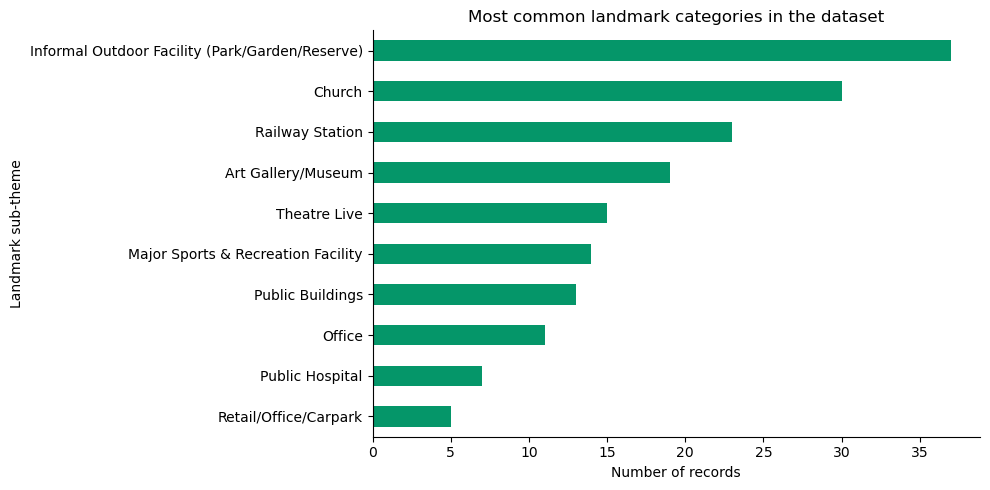


Data exploration summary:
Valid named walk records: 34
Valid landmark records: 242
Landmark records excluded during cleaning: 0
Most represented landmark category: Informal Outdoor Facility (Park/Garden/Reserve) (37 records)


In [9]:
print("Missing values in original walking dataset:")
display(walks.isna().sum().sort_values(ascending=False).head(12))

print("Landmark categories:")
category_counts = landmarks["sub_theme"].value_counts()
display(category_counts.head(12).rename("count").to_frame())

fig, ax = plt.subplots(figsize=(10, 5))
top_categories = category_counts.head(10).sort_values()
top_categories.plot(kind="barh", ax=ax, color=MOP_COLOURS["green"])
ax.set_title("Most common landmark categories in the dataset")
ax.set_xlabel("Number of records")
ax.set_ylabel("Landmark sub-theme")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("\nData exploration summary:")
print(f"Valid named walk records: {len(walks)}")
print(f"Valid landmark records: {len(landmarks)}")
print(f"Landmark records excluded during cleaning: {initial_landmark_rows - len(landmarks)}")
if not category_counts.empty:
    print(f"Most represented landmark category: {category_counts.index[0]} ({category_counts.iloc[0]} records)")


<div id="subsection-3-1" class="usecase-sub-section-heading"><b>3.1. Interpretation</b></div>

<div class="usecase-body">
The chart compares the number of landmark records in the most represented categories. This helps assess the kinds of attractions available for recommendation. Category frequency reflects how many features the dataset lists; it should not be interpreted as visitor preferences or popularity. The printed summary above reports the retrieved record counts, cleaned rows and leading category for the current API response.
</div>


<div id="section-4" class="usecase-section-heading"><b>4. User Selection Input</b></div>


<div class="usecase-body">
Choose a walking route and one or more landmark categories. The initial selection uses Street Art and Public Buildings when those options are available, giving an example with nearby landmarks in the previously tested dataset. If you change either selection, rerun the route preparation, recommendation, map and validation code cells in order.
</div>

In [10]:
walk_options = sorted(walks["name"].dropna().astype(str).unique().tolist())
landmark_options = sorted(landmarks["sub_theme"].dropna().astype(str).unique().tolist())
if not walk_options or not landmark_options:
    raise ValueError("No walking-tour or landmark-category options are available.")

# The defaults provide a useful example; readers can select any available options.
default_walk = "Street Art" if "Street Art" in walk_options else walk_options[0]
default_category = "Public Buildings" if "Public Buildings" in landmark_options else landmark_options[0]

walk_drop_list = widgets.Dropdown(
    options=walk_options,
    value=default_walk,
    description="Choose a walk:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="65%"),
)
landmark_drop_list = widgets.SelectMultiple(
    options=landmark_options,
    value=(default_category,),
    description="Landmark categories:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="75%", height="160px"),
)
display(walk_drop_list, landmark_drop_list)


Dropdown(description='Choose a walk:', index=9, layout=Layout(width='65%'), options=('Aboriginal Melbourne', '…

SelectMultiple(description='Landmark categories:', index=(32,), layout=Layout(height='160px', width='75%'), op…

<div id="section-5" class="usecase-section-heading"><b>5. Data Filtering and Route Preparation</b></div>



<div class="usecase-body">
Capture the visitor's selections and collect <b>all dataset records with the selected walking-tour name</b>. Some walks, including Street Art, have multiple records.

Each record's LineString or MultiLineString geometry is kept as a <b>separate route segment</b> so the map does not draw invented connections between them.

A shared name alone does not prove that the segments form one continuous navigable route.

Coordinates are used to estimate landmark proximity, not street-network walking distance.
</div>


In [11]:
def route_segments_from_record(row):
    """Return a list of route segments, each containing (latitude, longitude) pairs."""
    geometry = None
    if "geo_shape.geometry.coordinates" in row.index:
        geometry = {
            "type": row.get("geo_shape.geometry.type"),
            "coordinates": row.get("geo_shape.geometry.coordinates"),
        }
    elif "geo_shape" in row.index:
        geometry = row["geo_shape"]
        if isinstance(geometry, dict) and geometry.get("type") == "Feature":
            geometry = geometry.get("geometry")
    if not isinstance(geometry, dict):
        raise ValueError("Selected walk does not have a valid GeoJSON geometry.")

    coordinates = geometry.get("coordinates")
    geometry_type = geometry.get("type")
    if geometry_type == "LineString":
        raw_segments = [coordinates]
    elif geometry_type == "MultiLineString":
        raw_segments = coordinates
    else:
        raise ValueError(f"Unsupported or missing walk geometry type: {geometry_type!r}")

    if not isinstance(raw_segments, (list, tuple)):
        raise ValueError("Selected walking route has no valid coordinate sequences.")
    segments = []
    for raw_segment in raw_segments:
        converted = []
        if not isinstance(raw_segment, (list, tuple)):
            continue
        for pair in raw_segment:
            if not isinstance(pair, (list, tuple)) or len(pair) < 2:
                continue
            try:
                lon, lat = float(pair[0]), float(pair[1])
            except (TypeError, ValueError):
                continue
            # NaN fails these comparisons and is excluded automatically.
            if -180 <= lon <= 180 and -90 <= lat <= 90:
                converted.append((lat, lon))
        if converted:
            segments.append(converted)
    if not segments:
        raise ValueError("Selected walking route has no valid coordinates.")
    return segments


<div class="usecase-body">
Convert the selected route geometry into latitude–longitude pairs. All rows with the same route name are processed, but distinct line segments remain separate so the map never invents a connection between them. The displayed duration is taken from the dataset only if it is supplied; no walking time is estimated here.
</div>

In [12]:
selected_walk_name = walk_drop_list.value
selected_categories = tuple(landmark_drop_list.value)

if not selected_categories:
    raise ValueError(
        "Select at least one landmark category, then re-run this cell."
    )

# Get all records with the same walking-tour name.
selected_walk_rows = walks.loc[
    walks["name"].astype(str) == selected_walk_name
].copy()

if selected_walk_rows.empty:
    raise ValueError(
        "The selected walk is not found in the retrieved dataset."
    )

# Extract geometry from every matching record.
# Keep route segments separate.
route_segments = []

for _, walk_record in selected_walk_rows.iterrows():
    route_segments.extend(
        route_segments_from_record(walk_record)
    )

if not route_segments:
    raise ValueError(
        "The selected walk has no valid geographical route segments."
    )

# Combine coordinates for proximity calculations.
route_points = [
    point
    for segment in route_segments
    for point in segment
]

walk_coordinates = pd.DataFrame(
    route_points,
    columns=["lat", "lon"]
)

# Filter landmarks by selected categories.
selected_landmarks = (
    landmarks.loc[
        landmarks["sub_theme"].isin(selected_categories)
    ]
    .copy()
    .reset_index(drop=True)
)

# Duration may be unavailable in the dataset.
if "time" in selected_walk_rows.columns:
    durations = (
        selected_walk_rows["time"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    selected_walk_duration = (
        ", ".join(durations)
        if durations
        else "Not available"
    )
else:
    selected_walk_duration = "Not available"

# Display results.
print("Selected walking tour:", selected_walk_name)
print("Matching route records:", len(selected_walk_rows))
print("Separate route segments:", len(route_segments))
print("Total route coordinate samples:", len(walk_coordinates))
print("Duration recorded in data:", selected_walk_duration)
print("Landmarks in selected categories:", len(selected_landmarks))

display(
    selected_landmarks[
        ["feature_name", "sub_theme", "lat", "lon"]
    ].head(5)
)


Selected walking tour: Street Art
Matching route records: 3
Separate route segments: 3
Total route coordinate samples: 131
Duration recorded in data: Not available
Landmarks in selected categories: 13


,feature_name,sub_theme,lat,lon
0,State Library Victoria,Public Buildings,-37.809985,144.964330
1,Supreme Court,Public Buildings,-37.814149,144.957894
2,NGV International,Public Buildings,-37.823014,144.969343
3,Conservatory,Public Buildings,-37.814002,144.978560
4,Melbourne Childrens Court,Public Buildings,-37.812508,144.958299


<div id="section-6" class="usecase-section-heading"><b>6. Recommendation Model</b></div>


<div class="usecase-body">
For each landmark in the selected categories, calculate its <b>minimum geodesic (straight-line) distance to a recorded route coordinate</b>. This is a geographical proximity estimate, <b>not</b> a pedestrian travel distance or an exact distance to the continuous path. Where route vertices are widely spaced, the approximation may be less accurate.
</div>

<div class="usecase-body">
The example uses a <b>0.5 km maximum proximity</b> to highlight attractions relatively close to the route and shows up to <b>10 results</b> to keep the map legible. These are presentation choices, not empirically optimal settings. Both are configurable in the next cell and can be changed for testing; rerun the following cells afterward.
</div>

In [13]:
MAX_PROXIMITY_KM = 0.5     # Default proximity limit; edit to explore other values.
MAX_RECOMMENDATIONS = 10    # Show at most ten places so the map remains legible.

if MAX_PROXIMITY_KM <= 0 or MAX_RECOMMENDATIONS < 1:
    raise ValueError("Proximity limit must be positive and the result limit at least 1.")

def nearest_route_vertex_km(lat, lon, coordinate_array):
    """Shortest geodesic distance to a *recorded vertex* of the selected walk."""
    return min(geodesic((lat, lon), tuple(point)).km for point in coordinate_array)

# Work on a copy; do not mutate a filtered slice of the source dataset.
recommendations = selected_landmarks.copy()
if recommendations.empty:
    recommendations["proximity_km"] = pd.Series(dtype=float)
else:
    route_array = walk_coordinates[["lat", "lon"]].to_numpy(dtype=float)
    recommendations["proximity_km"] = [
        nearest_route_vertex_km(row.lat, row.lon, route_array)
        for row in recommendations.itertuples(index=False)
    ]

# One landmark = one recommendation, ranked by its closest route vertex.
recommendations = (
    recommendations.loc[recommendations["proximity_km"] <= MAX_PROXIMITY_KM]
    .sort_values("proximity_km", ascending=True)
    .drop_duplicates(subset=["feature_name", "lat", "lon"])
    .head(MAX_RECOMMENDATIONS)
    .reset_index(drop=True)
)

print(f"Recommended landmarks within {MAX_PROXIMITY_KM:.2f} km: {len(recommendations)}")
display(recommendations[["feature_name", "sub_theme", "proximity_km"]])


Recommended landmarks within 0.50 km: 6


,feature_name,sub_theme,proximity_km
0,Melbourne Town Hall,Public Buildings,0.076387
1,State Library Victoria,Public Buildings,0.091256
2,Melbourne Childrens Court,Public Buildings,0.139655
3,County Court Melbourne,Public Buildings,0.231138
4,Supreme Court,Public Buildings,0.317213
5,Commonwealth Law Courts,Public Buildings,0.317811


<div class="usecase-body">
If the result is empty, select additional landmark categories or increase <code>MAX_PROXIMITY_KM</code> in the previous cell and run it again. Do not present an empty result as a bug without first checking whether any places satisfy the chosen conditions.
</div>


<div id="section-7" class="usecase-section-heading"><b>7. Visualisation</b></div>


<div class="usecase-body">
Display the chosen walking route in MOP green and recommended attractions in MOP purple. Each marker popup shows the landmark's name, category and <b>approximate geographical proximity</b> to the route. The map is interactive but does not supply turn-by-turn directions, real-world accessibility checks or opening times.
</div>


In [16]:

walking_map = folium.Map(
    location=[
        walk_coordinates["lat"].mean(),
        walk_coordinates["lon"].mean()
    ],
    zoom_start=14,
    control_scale=True,
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr=(
        "Tiles &copy; Esri, HERE, Garmin, USGS, "
        "OpenStreetMap contributors and the GIS User Community"
    ),
)

# Display each route segment separately to avoid
# connecting unrelated sections with artificial lines.
for segment in route_segments:
    if len(segment) >= 2:
        plugins.AntPath(
            locations=segment,
            color=MOP_COLOURS["green"],
            pulse_color=MOP_COLOURS["yellow"],
            delay=1200,
            weight=5,
        ).add_to(walking_map)

    elif len(segment) == 1:
        folium.CircleMarker(
            location=segment[0],
            radius=3,
            color=MOP_COLOURS["green"],
            fill=True,
        ).add_to(walking_map)


# Add recommended landmarks to the map.
for row in recommendations.itertuples(index=False):

    popup_text = (
        f"<b>{html.escape(str(row.feature_name))}</b>"
        f"<br>Category: {html.escape(str(row.sub_theme))}"
        f"<br>Approx. geodesic proximity: "
        f"{row.proximity_km:.2f} km"
        "<br><small>Not a street-network walking distance</small>"
    )

    folium.CircleMarker(
        location=[row.lat, row.lon],
        radius=7,
        color=MOP_COLOURS["purple"],
        fill=True,
        fill_color=MOP_COLOURS["purple"],
        fill_opacity=0.85,
        popup=folium.Popup(
            popup_text,
            max_width=300,
        ),
        tooltip=str(row.feature_name),
    ).add_to(walking_map)


# Include the walking route and recommended landmarks
# within the visible map area.
map_points = walk_coordinates[["lat", "lon"]].copy()

if not recommendations.empty:
    map_points = pd.concat(
        [
            map_points,
            recommendations[["lat", "lon"]]
        ],
        ignore_index=True,
    )

map_bounds = [
    [
        float(map_points["lat"].min()),
        float(map_points["lon"].min())
    ],
    [
        float(map_points["lat"].max()),
        float(map_points["lon"].max())
    ],
]

if map_bounds[0] != map_bounds[1]:
    walking_map.fit_bounds(
        map_bounds,
        padding=(24, 24),
    )


# Display the selected walking tour information.
heading = html.escape(selected_walk_name)
categories_html = html.escape(", ".join(selected_categories))

walking_map.get_root().html.add_child(
    folium.Element(
        f'<h3 style="text-align:center;'
        f'color:{MOP_COLOURS["green"]}">'
        f'Self-Designed Walking Tour: {heading}</h3>'
        f'<p style="text-align:center">'
        f'Selected categories: {categories_html}'
        f' | Approximate nearby landmarks: '
        f'{len(recommendations)}</p>'
    )
)


# Add a map legend using the official MOP colours.
legend = (
    '<div style="position:fixed;bottom:20px;left:20px;'
    'z-index:9999;background:white;'
    'border:1px solid #cccccc;border-radius:5px;'
    'padding:8px 12px;font-size:12px;'
    'box-shadow:0 1px 4px #cccccc">'
    f'<span style="color:{MOP_COLOURS["green"]}">'
    '━━</span> Recorded route &nbsp;'
    f'<span style="color:{MOP_COLOURS["purple"]}">'
    '●</span> Recommended landmark'
    '</div>'
)

walking_map.get_root().html.add_child(
    folium.Element(legend)
)


# Save and display the completed walking tour map.
OUTPUT_MAP_FILE = "UC00008_walking_tour_map.html"

walking_map.save(OUTPUT_MAP_FILE)

print(f"Map saved to {OUTPUT_MAP_FILE}")

display(walking_map)



Map saved to UC00008_walking_tour_map.html


<div id="section-8" class="usecase-section-heading"><b>8. Validation and Interpretation</b></div>



<div class="usecase-body">
Check the results rather than assuming the notebook is correct simply because it runs.

For a tour name that appears in multiple rows (for example, Street Art), confirm that the number of route records, displayed segments and geographic extent match the dataset.

Segments are shown separately rather than artificially joined; you should verify whether these represent connected sections or alternative paths.

Test a category with nearby landmarks, a combination with no recommendations, and a different tour.

Compare several proximity values with manual geodesic calculations and record the results before requesting review.
</div>


In [17]:
# Consistency checks for the currently selected walking tour.
# These do not replace checking the rendered map or the live API.
assert not walk_coordinates.empty, "The route must include valid coordinates."
assert len(route_segments) >= len(selected_walk_rows), (
    "Each selected dataset record should supply at least one route segment."
)
assert len(walk_coordinates) == sum(len(segment) for segment in route_segments)
assert {"lat", "lon"}.issubset(walk_coordinates.columns)
assert {"feature_name", "sub_theme", "proximity_km"}.issubset(recommendations.columns)
assert len(recommendations) <= MAX_RECOMMENDATIONS
assert recommendations["sub_theme"].isin(selected_categories).all(), (
    "Recommendations should only include selected categories."
)
assert not recommendations.duplicated(subset=["feature_name", "lat", "lon"]).any(), (
    "Duplicate recommended landmarks were found."
)

if not recommendations.empty:
    assert recommendations["proximity_km"].ge(0).all()
    assert recommendations["proximity_km"].le(MAX_PROXIMITY_KM).all()
    assert recommendations["proximity_km"].is_monotonic_increasing

print("Validation checks passed for:", selected_walk_name)
print(f"Route records: {len(selected_walk_rows)} | Segments: {len(route_segments)}")
print(f"Recommendations: {len(recommendations)} | Limit: {MAX_PROXIMITY_KM:.2f} km")
print("Manual map review and current-data verification are still required.")

Validation checks passed for: Street Art
Route records: 3 | Segments: 3
Recommendations: 6 | Limit: 0.50 km
Manual map review and current-data verification are still required.


<div id="subsection-8-1" class="usecase-sub-section-heading"><b>8.1. Manual Test Evidence</b></div>

<div class="usecase-body">
The following observations were recorded in separate Jupyter runs in November 2026 using City of Melbourne data. They illustrate test coverage; they are not guaranteed results after future API updates.
</div>

| Test | Selected walking tour | Selected categories | Limit | Observed result |
|---|---|---|---:|---|
| Multiple route records | Street Art | Public Buildings | 0.5 km | 3 records, 3 segments, 131 vertices; 6 landmarks |
| Empty recommendation set | Aboriginal Melbourne | Aquarium | 0.5 km | 1 record, 32 vertices; 0 landmarks; map displayed |
| Proximity sensitivity | Aboriginal Melbourne | Aquarium | 1.0 km | Melbourne Aquarium at approximately 0.958 km |
| Different walking tour | Classic Icons and Architecture | Church | 0.5 km | 3 records, 3 segments, 278 vertices; 7 landmarks |

<div class="usecase-body">
Multi-segment routes, different selections, empty results and configurable proximity thresholds were tested. A final review should also inspect the Folium map popups, fresh-kernel execution and current API data. Recommendations do not account for accessibility, opening hours, closures, weather, path conditions or personal safety.
</div>


<div id="conclusion" class="usecase-unnumbered-heading"><b>Conclusion</b></div>


<div class="usecase-body">
The use case meets the original visitor scenario by letting a Melbourne visitor choose a self-guided walking tour and select one or more categories of places they are interested in. It then identifies landmarks near the recorded tour coordinates, ranks up to ten matching places by estimated geographical proximity and presents the selected route and suggested attractions on an interactive Folium map. This helps the visitor discover relevant places and plan a personalised sightseeing experience.
</div>

<div class="usecase-body">
The analysis retrieves City of Melbourne Open Data through its API, validates and cleans the relevant fields, examines landmark categories and processes separate walking-route geometries without creating artificial joins. Testing demonstrated different tour and category selections, multiple route segments and cases with no nearby recommendations.
</div>

<div class="usecase-body">
The recommendations are exploratory aids rather than turn-by-turn navigation. Proximity is measured to the nearest recorded route coordinate, not along streets or walking paths. Opening hours, accessibility, temporary closures, weather, walking conditions and personal safety are not considered. Possible future improvements include pedestrian-network routing and additional maintained accessibility and operating-hours data.
</div>
